# Fit-Modes Method Comparison Curves

This notebook assembles the paper-figure curve preview for the OASIS rank-9
case and LungCT cases 01/08.

Panel A compares image-registration similarity curves. IDIR uses the newly
rerun matched diagnostic metric every 10 epochs; SINR/DirectCP use their
per-epoch matched data-loss histories. LungCT DirectCP 4-stage registration
uses the existing posthoc `finest_data_loss` diagnostic, not stage-domain
training loss. Panel B compares target-field fitting MSE curves against the
SITReg target for OASIS and the pTVReg target for LungCT; LungCT DirectCP
4-stage field fitting uses the rerun posthoc finest-domain MSE diagnostics.

The final section builds a preliminary field-fit-only figure with relative
target-field MSE (`rMSE`) and relative target-field RMSE (`rRMSE`). It includes
both OASIS rank-9 SITReg-field and Greedy-field fitting, then LungCT pTVReg
case01/case08 field fitting. The relative metrics reuse the same masked
normalized-grid MSE histories and divide by the target-field power in the same
mask and coordinate convention. A second rRMSE-only trajectory figure compares
the requested learning rates for IDIR, SINR cps4, DirectCP cps4, and available
LungCT DirectCP 4-stage diagnostics.


## Figure Message

The field-fitting objective is easy for local-control spline methods: DirectCP
fits the target fields very well on all three cases. Registration tells a
different story. OASIS is comparatively forgiving, LungCT case01 is easier, and
LungCT case08 exposes the need for a multistage optimization path rather than
a single cps4 spline solve.


In [1]:
%matplotlib inline
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

pd.options.display.max_columns = 80
pd.options.display.max_colwidth = 120

candidates = [
    Path.cwd(),
    Path("/homebase/code_sync/inrorspline/experiments/2026-06-26_fit_modes_paper_figure"),
    Path("experiments/2026-06-26_fit_modes_paper_figure").resolve(),
]
for candidate in candidates:
    if (candidate / "fit_modes_method_comparison.py").exists():
        REVIEW_ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate fit_modes_method_comparison.py")

sys.path.insert(0, str(REVIEW_ROOT))
print(REVIEW_ROOT)


/homebase/code_sync/inrorspline/experiments/2026-06-26_fit_modes_paper_figure


In [2]:
from fit_modes_method_comparison import (
    RELATIVE_FIELD_CASE_ORDER,
    build_rrmse_lr_trajectory_outputs,
    load_curves,
    load_relative_field_fit_curves,
    make_main_figure,
    make_relative_field_fit_figure,
    relative_field_curve_summary,
    save_relative_field_fit_figure,
    save_main_figure,
    selected_runs,
    curve_summary,
    target_power_summary,
)


## Selected Runs

One LR is selected per method/case/task. Registration IDIR is fixed to
`lr=1e-4` because that is the matched-metric rerun. Other registration LRs are
selected by final label metric: Dice for OASIS and native-crop snap TRE for
LungCT, except LungCT DirectCP 4-stage, which is fixed to the existing
`lr=1e-2` finest-domain diagnostic run. Field-fitting LRs are selected by
objective target-field MSE.


In [3]:
selection = selected_runs()
display(selection.drop(columns=["run_dir"]))
selection.to_csv(REVIEW_ROOT / "fit_modes_method_comparison_selected_runs.csv", index=False)


,case,task,method,lr,selection_metric,selection_value,curve_metric
0,OASIS rank-9,SITReg field fit,IDIR,0.0001,min objective field MSE,1.385626e-05,masked normalized-grid MSE
1,OASIS rank-9,SITReg field fit,SINR cps4,0.0010,min objective field MSE,8.539376e-06,masked normalized-grid MSE
2,OASIS rank-9,SITReg field fit,DirectCP cps4,0.0100,min objective field MSE,7.776494e-06,masked normalized-grid MSE
3,OASIS rank-9,registration,IDIR,0.0001,fixed to matched-eval rerun,8.110368e-01,global NCC loss
4,OASIS rank-9,registration,SINR cps4,0.0001,max final Dice among completed LR sweep,8.295876e-01,global NCC loss
5,OASIS rank-9,registration,DirectCP cps4,0.0010,max final Dice among completed LR sweep,8.267911e-01,global NCC loss
6,LungCT case01,pTVReg field fit,IDIR,0.0010,min objective field MSE,2.511078e-06,masked normalized-grid MSE
7,LungCT case01,pTVReg field fit,SINR cps4,0.0010,min objective field MSE,2.451089e-07,masked normalized-grid MSE
8,LungCT case01,pTVReg field fit,DirectCP cps4,0.0100,min objective field MSE,2.846273e-08,masked normalized-grid MSE
9,LungCT case01,pTVReg field fit,DirectCP 4stage cps4,0.0100,fixed to rerun finest-domain diagnostic,2.846052e-08,masked normalized-grid MSE


## Curve Inputs

IDIR registration curves have 251 points: epoch 1 plus every 10 epochs through
2500. Other registration histories are per-epoch curves. LungCT DirectCP
4-stage registration uses `finest_data_loss`. LungCT DirectCP 4-stage
field-fitting also uses `finest_data_loss` from the rerun diagnostic histories:
coarse stages are evaluated every 50 epochs, and the final full-resolution
stage is evaluated every epoch.


In [4]:
reg_curves, field_curves = load_curves(selection)
summary = pd.concat(
    [
        curve_summary(reg_curves).assign(curve_group="registration"),
        curve_summary(field_curves).assign(curve_group="field_fit"),
    ],
    ignore_index=True,
)
display(summary.drop(columns=["source"]))
summary.to_csv(REVIEW_ROOT / "fit_modes_method_comparison_curve_summary.csv", index=False)


,case,task,method,lr,points,epoch_min,epoch_max,value_start,value_end,note,curve_group
0,OASIS rank-9,registration,IDIR,0.0001,251,1.0,2500.0,-0.884194,-9.750215e-01,IDIR matched global NCC evaluated every 10 epochs.,registration
1,OASIS rank-9,registration,SINR cps4,0.0001,2500,1.0,2500.0,-0.839242,-9.910164e-01,Per-epoch SINR global NCC data loss.,registration
2,OASIS rank-9,registration,DirectCP cps4,0.0010,2500,1.0,2500.0,-0.900681,-9.911135e-01,Per-epoch SINR global NCC data loss.,registration
3,LungCT case01,registration,IDIR,0.0001,251,1.0,2500.0,5.538059,2.817244e+00,IDIR matched pTV LCC evaluated every 10 epochs.,registration
4,LungCT case01,registration,SINR cps4,0.0010,2500,1.0,2500.0,5.278737,2.627739e+00,Per-epoch pTV LCC data loss.,registration
5,LungCT case01,registration,DirectCP cps4,0.0100,2500,1.0,2500.0,3.932446,2.634305e+00,Per-epoch pTV LCC data loss.,registration
6,LungCT case01,registration,DirectCP 4stage cps4,0.0100,2500,1.0,2500.0,3.932446,2.613967e+00,Posthoc finest-domain pTV LCC diagnostic; training still used stage-domain loss.,registration
7,LungCT case08,registration,IDIR,0.0001,251,1.0,2500.0,9.890514,5.032755e+00,IDIR matched pTV LCC evaluated every 10 epochs.,registration
8,LungCT case08,registration,SINR cps4,0.0010,2500,1.0,2500.0,9.646268,5.174368e+00,Per-epoch pTV LCC data loss.,registration
9,LungCT case08,registration,DirectCP cps4,0.0100,2500,1.0,2500.0,9.068019,4.995810e+00,Per-epoch pTV LCC data loss.,registration


## Main Comparison Figure

The display applies a centered rolling median only for readability. Set
`smooth=False` in `make_main_figure(...)` below to inspect unsmoothed curves.
The saved PDF/PNG use the same figure shown inline.


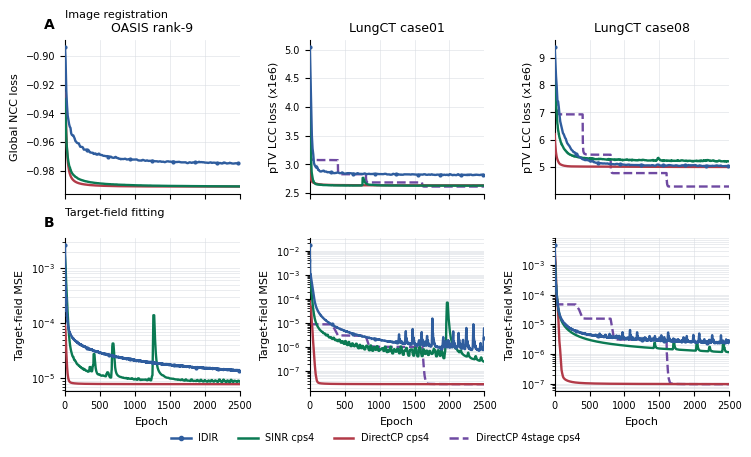

Existing combined-figure files are not rewritten by this cell:
- `pdf`: `/homebase/code_sync/inrorspline/experiments/2026-06-26_fit_modes_paper_figure/fit_modes_method_comparison_curves.pdf`
- `png`: `/homebase/code_sync/inrorspline/experiments/2026-06-26_fit_modes_paper_figure/fit_modes_method_comparison_curves.png`

In [5]:
fig = make_main_figure(reg_curves, field_curves, smooth=True)
display(fig)
plt.close(fig)
existing_outputs = {
    "pdf": REVIEW_ROOT / "fit_modes_method_comparison_curves.pdf",
    "png": REVIEW_ROOT / "fit_modes_method_comparison_curves.png",
}
display(Markdown(
    "Existing combined-figure files are not rewritten by this cell:\n"
    + "\n".join([f"- `{name}`: `{path}`" for name, path in existing_outputs.items()])
))


## Preliminary Relative Field-Fit Figure

This section leaves the image-registration panel unchanged and replots only the
target-field fitting curves. It adds the OASIS Greedy-field target beside the
OASIS SITReg-field target. The denominator is inferred per target from the
selected DirectCP cps4 first point: DirectCP starts from zero controls, so its
epoch-1 masked MSE equals the masked target-field component power.


In [6]:
relative_field_curves = load_relative_field_fit_curves(selection)
target_powers = target_power_summary(relative_field_curves, RELATIVE_FIELD_CASE_ORDER)
display(target_powers)
target_powers.to_csv(REVIEW_ROOT / "fit_modes_target_power_summary.csv", index=False)


,case,target_power_component_mean,target_rms_component,target_power_precheck_component_mean,relative_difference_vs_precheck,target_power_units,target_power_domain,target_power_source,eps
0,OASIS SITReg,0.000566,0.023800,0.000566,3.241559e-08,normalized_grid_displacement_squared,SITReg field fit,DirectCP cps4 epoch-1 masked normalized-grid MSE; zero-control initialization makes this mean(target_u ** 2),1.000000e-12
1,OASIS Greedy,0.000668,0.025836,0.000668,3.060417e-08,normalized_grid_displacement_squared,Greedy field fit,DirectCP cps4 epoch-1 masked normalized-grid MSE; zero-control initialization makes this mean(target_u ** 2),1.000000e-12
2,LungCT case01,0.000744,0.027276,0.000744,9.762905e-08,normalized_grid_displacement_squared,pTVReg field fit,DirectCP cps4 epoch-1 masked normalized-grid MSE; zero-control initialization makes this mean(target_u ** 2),1.000000e-12
3,LungCT case08,0.007239,0.085084,0.007239,8.645742e-08,normalized_grid_displacement_squared,pTVReg field fit,DirectCP cps4 epoch-1 masked normalized-grid MSE; zero-control initialization makes this mean(target_u ** 2),1.000000e-12


In [7]:
relative_summary = relative_field_curve_summary(relative_field_curves, target_powers)
display(
    relative_summary[
        [
            "case",
            "method",
            "lr",
            "target_power_component_mean",
            "rMSE_start",
            "rMSE_epoch10",
            "rMSE_end",
            "rRMSE_percent_start",
            "rRMSE_percent_epoch10",
            "rRMSE_percent_end",
            "has_epoch10",
        ]
    ]
)
relative_summary.to_csv(REVIEW_ROOT / "fit_modes_relative_field_fit_curve_summary.csv", index=False)


,case,method,lr,target_power_component_mean,rMSE_start,rMSE_epoch10,rMSE_end,rRMSE_percent_start,rRMSE_percent_epoch10,rRMSE_percent_end,has_epoch10
0,OASIS SITReg,IDIR,0.0001,0.000566,7.884174,0.615571,0.024391,280.787719,78.458361,15.617659,True
1,OASIS SITReg,SINR cps4,0.0010,0.000566,5.154120,2.170106,0.015216,227.026879,147.312784,12.335216,True
2,OASIS SITReg,DirectCP cps4,0.0100,0.000566,1.000000,0.134840,0.013729,100.000000,36.720509,11.717126,True
3,OASIS Greedy,IDIR,0.0001,0.000668,6.261654,0.625491,0.009011,250.232981,79.087993,9.492840,True
4,OASIS Greedy,SINR cps4,0.0010,0.000668,3.982798,1.701391,0.004690,199.569495,130.437368,6.848663,True
5,OASIS Greedy,DirectCP cps4,0.0100,0.000668,1.000000,0.120432,0.003126,100.000000,34.703251,5.591003,True
6,LungCT case01,IDIR,0.0010,0.000744,3.585885,1.438444,0.003642,189.364339,119.935148,6.034655,True
7,LungCT case01,SINR cps4,0.0010,0.000744,2.331959,0.916243,0.000331,152.707532,95.720582,1.818093,True
8,LungCT case01,DirectCP cps4,0.0100,0.000744,1.000000,0.058937,0.000038,100.000000,24.276998,0.618516,True
9,LungCT case01,DirectCP 4stage cps4,0.0100,0.000744,1.000000,NaN,0.000038,100.000000,NaN,0.618492,False


- `pdf`: `/homebase/code_sync/inrorspline/experiments/2026-06-26_fit_modes_paper_figure/fit_modes_relative_field_fit_prelim_curves.pdf`
- `png`: `/homebase/code_sync/inrorspline/experiments/2026-06-26_fit_modes_paper_figure/fit_modes_relative_field_fit_prelim_curves.png`

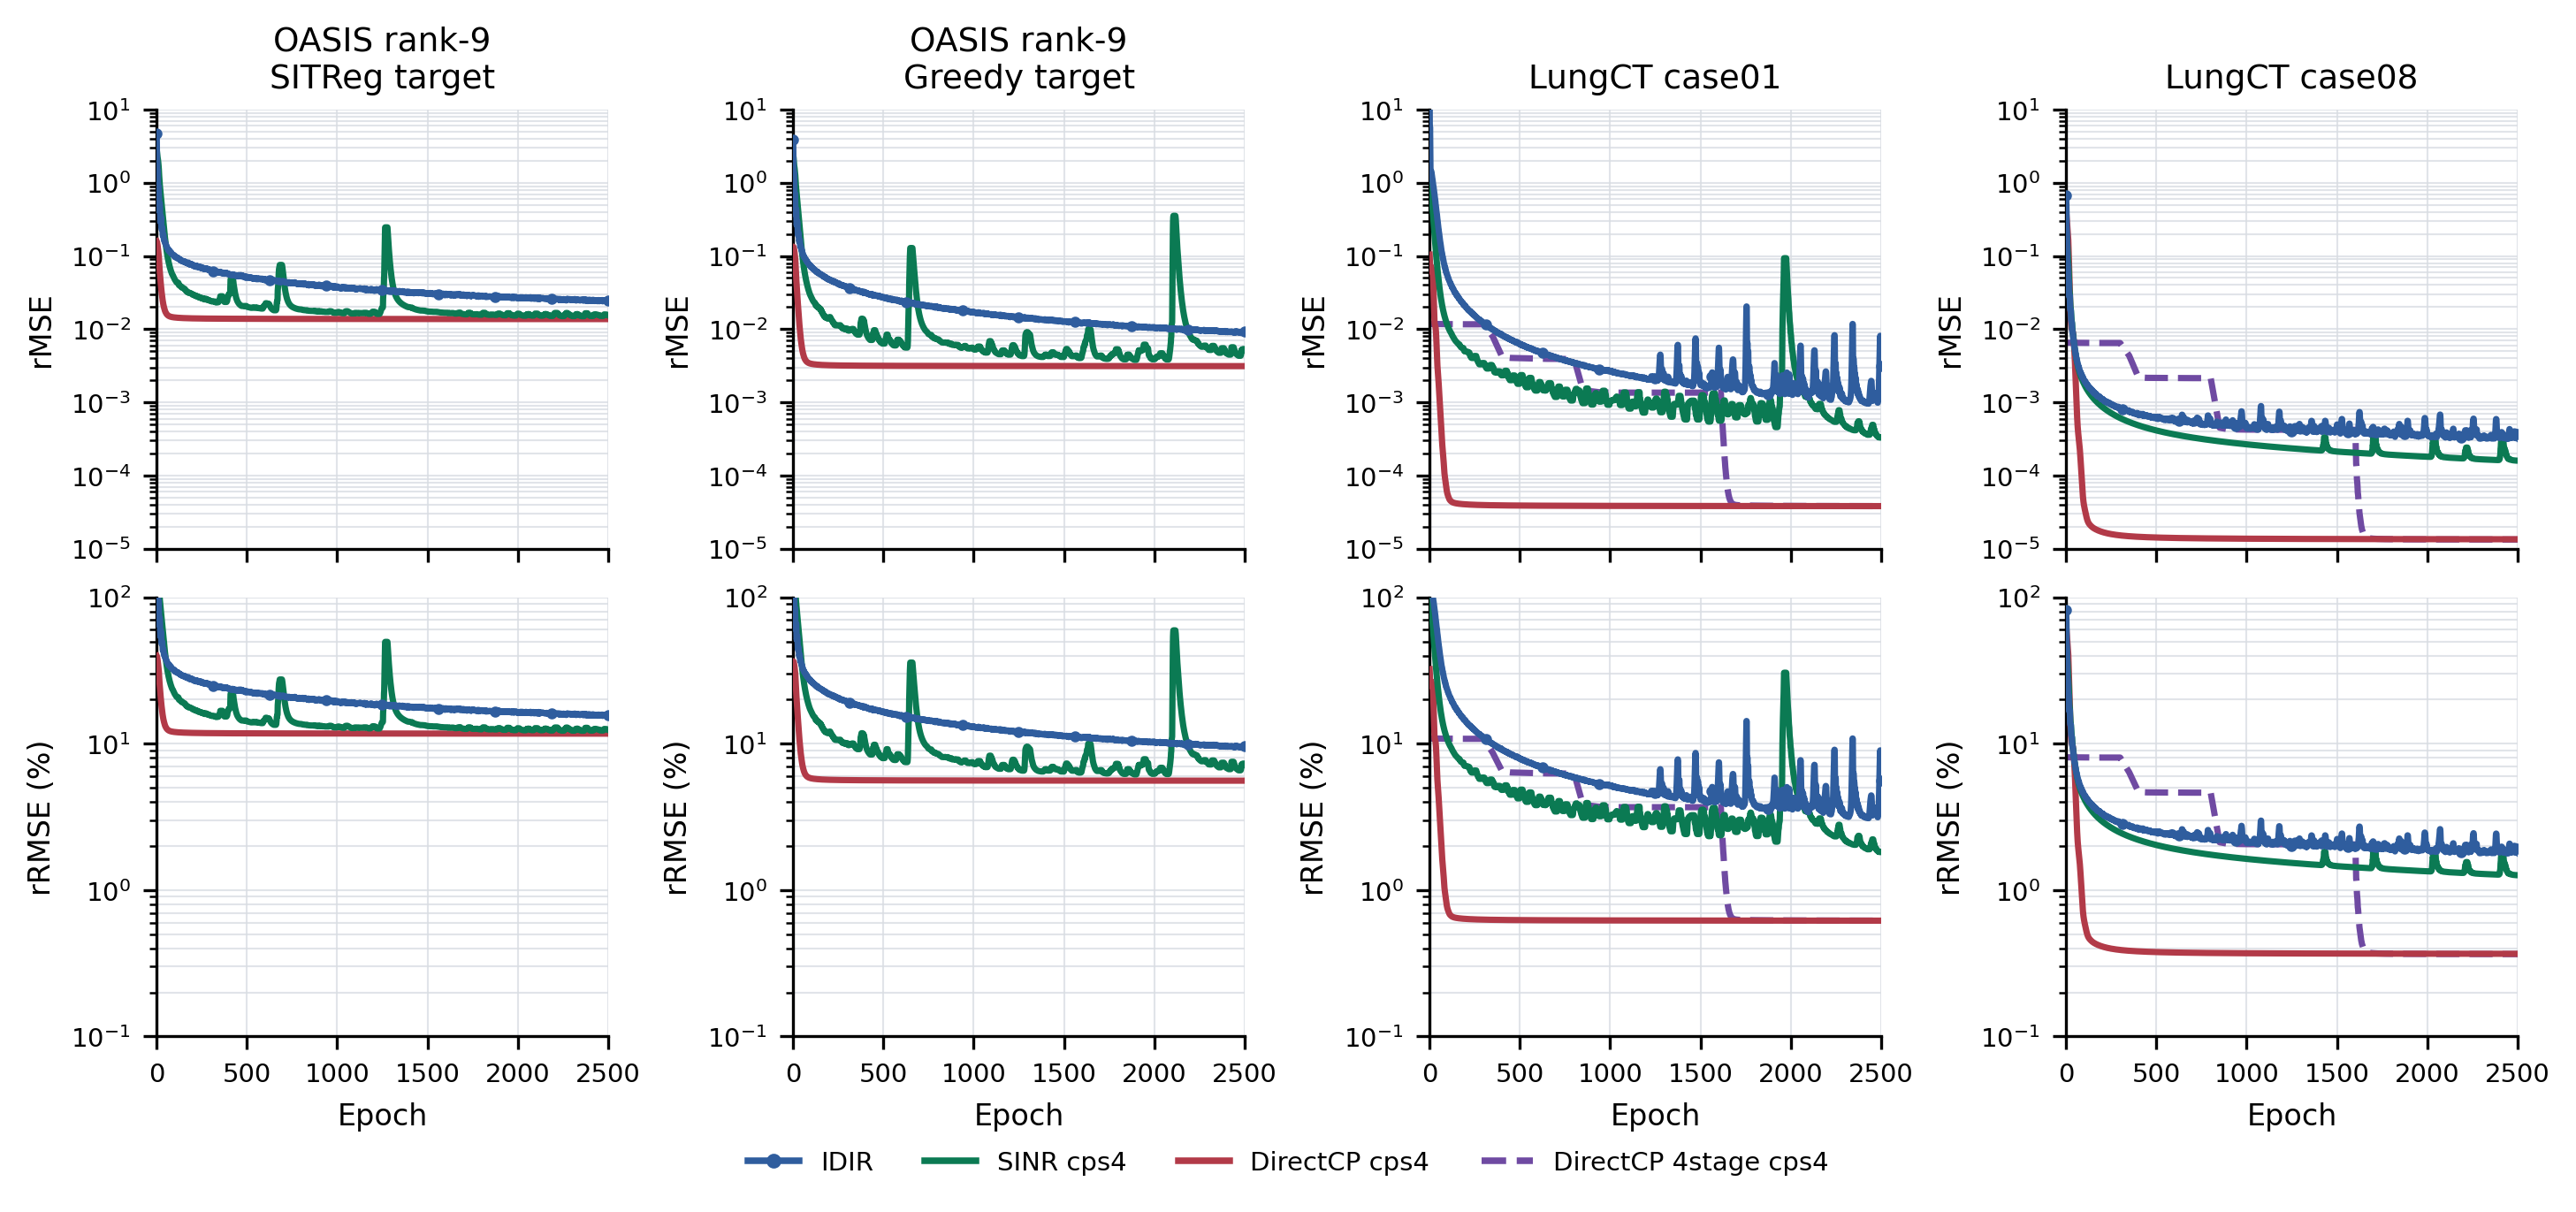

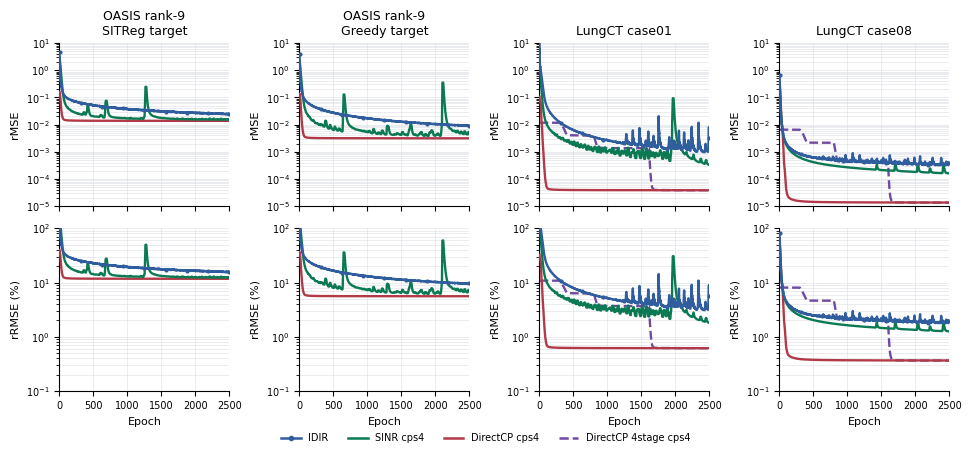

In [8]:
relative_fig = make_relative_field_fit_figure(
    relative_field_curves,
    target_powers,
    smooth=True,
    case_order=RELATIVE_FIELD_CASE_ORDER,
)
relative_outputs = save_relative_field_fit_figure(relative_fig)
display(Markdown("\n".join([f"- `{name}`: `{path}`" for name, path in relative_outputs.items()])))
display(Image(filename=str(relative_outputs["png"])))


## rRMSE Learning-Rate Trajectory Figure

This field-fit-only figure compares requested learning-rate trajectories:
IDIR and SINR cps4 at `1e-3`/`1e-4`, DirectCP cps4 at
`1e-2`/`1e-3`/`1e-4`, and LungCT DirectCP 4-stage at
`1e-2`/`1e-3`/`1e-4`. DirectCP 4-stage is not shown for OASIS because no
OASIS 4-stage field-fit run is included in this comparison. The shared y-axis
is capped at `100%` rRMSE.


,case,task,method,lr,lr_label,requested,available,points,note
0,OASIS SITReg,field_fit,IDIR,0.0010,1e-3,True,True,2500,Requested LR trajectory for masked normalized-grid target-field MSE in the OASIS field-fit sweep.
1,OASIS SITReg,field_fit,IDIR,0.0001,1e-4,True,True,2500,Requested LR trajectory for masked normalized-grid target-field MSE in the OASIS field-fit sweep.
2,OASIS SITReg,field_fit,SINR cps4,0.0010,1e-3,True,True,2500,Requested LR trajectory for masked normalized-grid target-field MSE in the OASIS field-fit sweep.
3,OASIS SITReg,field_fit,SINR cps4,0.0001,1e-4,True,True,2500,Requested LR trajectory for masked normalized-grid target-field MSE in the OASIS field-fit sweep.
4,OASIS SITReg,field_fit,DirectCP cps4,0.0100,1e-2,True,True,2500,Requested LR trajectory for masked normalized-grid target-field MSE in the OASIS field-fit sweep.
5,OASIS SITReg,field_fit,DirectCP cps4,0.0010,1e-3,True,True,2500,Requested LR trajectory for masked normalized-grid target-field MSE in the OASIS field-fit sweep.
6,OASIS SITReg,field_fit,DirectCP cps4,0.0001,1e-4,True,True,2500,Requested LR trajectory for masked normalized-grid target-field MSE in the OASIS field-fit sweep.
7,OASIS SITReg,field_fit,DirectCP 4stage cps4,0.0100,1e-2,True,False,0,Not run for OASIS; no OASIS DirectCP 4-stage field-fit trajectory is included.
8,OASIS SITReg,field_fit,DirectCP 4stage cps4,0.0010,1e-3,True,False,0,Not run for OASIS; no OASIS DirectCP 4-stage field-fit trajectory is included.
9,OASIS SITReg,field_fit,DirectCP 4stage cps4,0.0001,1e-4,True,False,0,Not run for OASIS; no OASIS DirectCP 4-stage field-fit trajectory is included.


,case,method,lr_label,points,rRMSE_percent_start,rRMSE_percent_epoch10,rRMSE_percent_epoch50,rRMSE_percent_end,has_epoch10,has_epoch50
0,OASIS SITReg,IDIR,1e-3,2500,280.787719,147.652410,70.026277,17.515378,True,True
1,OASIS SITReg,IDIR,1e-4,2500,280.787719,78.458361,38.384715,15.617659,True,True
2,OASIS SITReg,SINR cps4,1e-3,2500,227.026879,147.312784,39.200760,12.335216,True,True
3,OASIS SITReg,SINR cps4,1e-4,2500,227.026879,80.918204,32.901690,12.976135,True,True
4,OASIS SITReg,DirectCP cps4,1e-2,2500,100.000000,36.720509,13.082680,11.717126,True,True
5,OASIS SITReg,DirectCP cps4,1e-3,2500,100.000000,75.685653,27.761250,11.798719,True,True
6,OASIS SITReg,DirectCP cps4,1e-4,2500,100.000000,97.361426,86.389017,12.887542,True,True
7,OASIS Greedy,IDIR,1e-3,2500,250.232981,140.353763,67.096012,10.879691,True,True
8,OASIS Greedy,IDIR,1e-4,2500,250.232981,79.087993,34.484071,9.492840,True,True
9,OASIS Greedy,SINR cps4,1e-3,2500,199.569495,130.437368,33.602850,6.848663,True,True


- `pdf`: `/homebase/code_sync/inrorspline/experiments/2026-06-26_fit_modes_paper_figure/fit_modes_rrmse_lr_trajectory_curves.pdf`
- `png`: `/homebase/code_sync/inrorspline/experiments/2026-06-26_fit_modes_paper_figure/fit_modes_rrmse_lr_trajectory_curves.png`

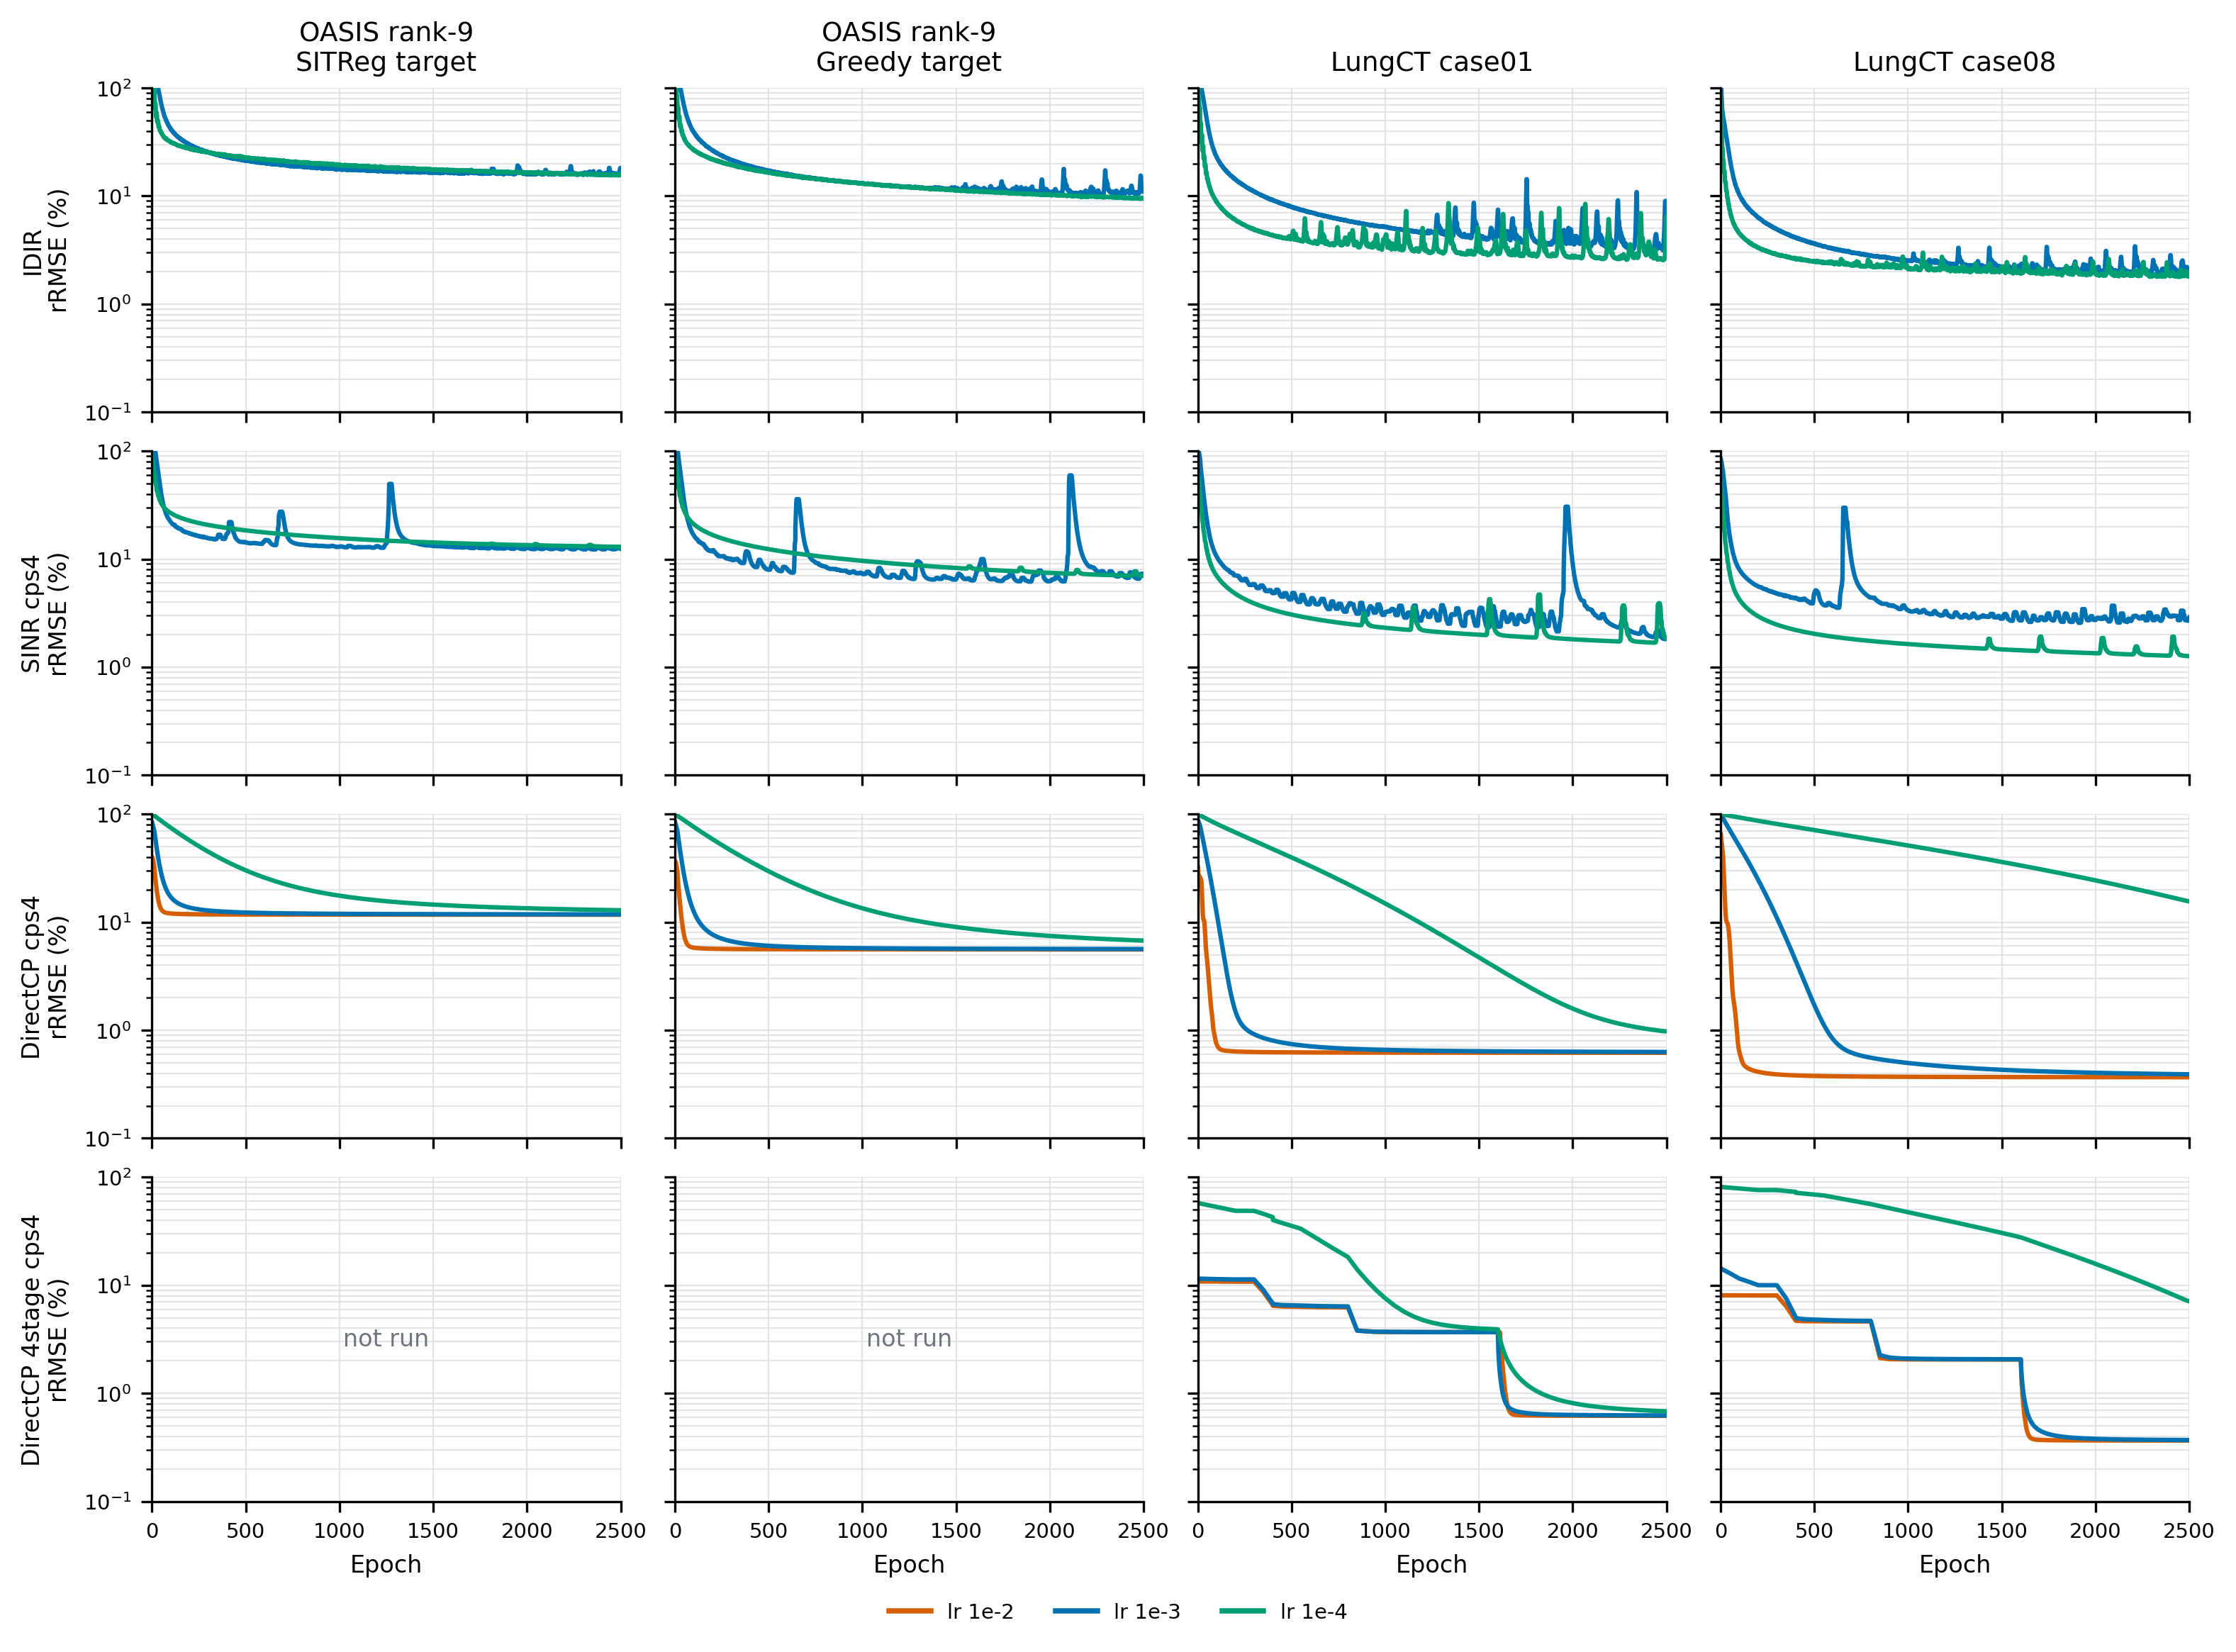

In [9]:
lr_selected, lr_target_powers, lr_summary, lr_fig, lr_outputs = build_rrmse_lr_trajectory_outputs()
display(lr_selected.drop(columns=["source"]))
display(
    lr_summary[
        [
            "case",
            "method",
            "lr_label",
            "points",
            "rRMSE_percent_start",
            "rRMSE_percent_epoch10",
            "rRMSE_percent_epoch50",
            "rRMSE_percent_end",
            "has_epoch10",
            "has_epoch50",
        ]
    ]
)
display(Markdown("\n".join([f"- `{name}`: `{path}`" for name, path in lr_outputs.items()])))
display(Image(filename=str(lr_outputs["png"])))
plt.close(lr_fig)


## Output Files

The notebook writes or updates:

- `fit_modes_method_comparison_selected_runs.csv`
- `fit_modes_method_comparison_curve_summary.csv`
- `fit_modes_relative_field_fit_prelim_curves.pdf`
- `fit_modes_relative_field_fit_prelim_curves.png`
- `fit_modes_relative_field_fit_curve_summary.csv`
- `fit_modes_target_power_summary.csv`
- `fit_modes_rrmse_lr_trajectory_curves.pdf`
- `fit_modes_rrmse_lr_trajectory_curves.png`
- `fit_modes_rrmse_lr_trajectory_curve_summary.csv`
- `fit_modes_rrmse_lr_trajectory_selected_runs.csv`
